# ASRO pilot study - DINOv2-base (standard and with registers)

**Before you start:** Runtime -> Change runtime type -> **T4 GPU** -> Save. Then **Runtime -> Run all**. Everything runs in order (about 30-40 minutes). Each cell ends with what you should see.

**Fresh start** (after an error, a new data set or new settings): change settings only in **Cell 1**, then Runtime -> Restart session -> Run all. With `FRESH_START = True` old results are deleted; downloaded images are kept.

| Part | Cells | Question for the proposal |
|---|---|---|
| Set-up | 1-4 | Settings, the two models, the images, shared functions |
| **A. Where is the concentration?** | 5-8 | Stable rank per layer, two mechanisms, randomised SVD, where the outlier tokens are, **Figure 1** |
| **B. Is it harmful or useful?** | 9-12 | Linear probe, exact loss change when damping each top-8 direction, fast one-pass score |
| **C. Does harm appear under shift?** | 13 | The same test on blurred, noisy and higher-resolution images |
| Summary | 14-15 | All proposal numbers in one block (paste it into the Claude app), zip of all results |

All results go to the folder `asro_pilot_study` (folder icon on the left). Cell 15 zips and downloads them.

In [1]:
# Cell 1 - SETUP AND SETTINGS (the only cell you ever need to edit)
# What this cell does and why: installs and imports the packages, fixes the random seed (same images every time),
# picks the GPU and keeps ALL settings in one place, so a fresh start never needs changes anywhere else.
!pip -q install transformers torchvision matplotlib scipy pandas
import os, time, json, shutil, random
import numpy as np, pandas as pd, torch, torch.nn.functional as F
import matplotlib.pyplot as plt, matplotlib.patches as mpatches
from scipy.stats import spearmanr
from PIL import Image, ImageFilter

SEED = 0
N_IMAGES = 32                  # evaluation images (Imagenette validation set; the same 32 as pilot v0)
N_TRAIN_PER_CLASS = 50         # training images per class for the linear probe (500 in total)
PILOT_LAYERS = [8, 9, 10, 12]  # layers used in Parts B and C (1-based)
K = 8                          # number of top singular directions
DELTAS = [0.1, 1.0]            # damping strength: 0.1 = small correction, 1.0 = direction removed
N_RANDOM = 8                   # random directions per image for the noise floor tau
OUTLIER_FACTOR = 10            # a token is an outlier if its norm is > 10 x the median token norm
SHIFTS = ["blur", "noise", "high-res 448"]
FIG1B_IMAGES = [3, 4]          # the two images shown in Figure 1b
MODEL_NAMES = {"standard": "facebook/dinov2-base", "registers": "facebook/dinov2-with-registers-base"}
FRESH_START = True             # True = delete old results first

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
ROOT = "/content" if os.path.isdir("/content") else "."
OUT = os.path.join(ROOT, "asro_pilot_study"); DATA_DIR = os.path.join(ROOT, "data")
if FRESH_START and os.path.isdir(OUT):
    shutil.rmtree(OUT)
os.makedirs(OUT, exist_ok=True); os.makedirs(DATA_DIR, exist_ok=True)
T_START = time.time()
print("device:", device, "|", torch.cuda.get_device_name(0) if device == "cuda" else "NO GPU - Runtime -> Change runtime type -> T4 GPU")
print("results folder:", OUT)
print("Expected: device: cuda | Tesla T4")

device: cuda | Tesla T4
results folder: /content/asro_pilot_study
Expected: device: cuda | Tesla T4


In [2]:
# Cell 2 - LOAD THE TWO MODELS: DINOv2-base and DINOv2-base with registers (both frozen)
# What this cell does and why: the registers model is the control - it has no high-norm outlier tokens, so comparing
# the two separates the two mechanisms of concentration. We never change the weights.
from transformers import AutoImageProcessor, AutoModel
MODELS = {}
for name, hf in MODEL_NAMES.items():
    proc = AutoImageProcessor.from_pretrained(hf)
    mdl = AutoModel.from_pretrained(hf).to(device).eval()
    for p in mdl.parameters():
        p.requires_grad_(False)
    MODELS[name] = dict(model=mdl, processor=proc, n_front=1 + getattr(mdl.config, "num_register_tokens", 0))
    print(f"{name:9s}: {hf}, {len(mdl.encoder.layer)} layers, {MODELS[name]['n_front'] - 1} register tokens")
print("Expected: standard 12 layers, 0 register tokens; registers 12 layers, 4 register tokens")

preprocessor_config.json:   0%|          | 0.00/436 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/548 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

standard : facebook/dinov2-base, 12 layers, 0 register tokens


... (2 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/224 [00:00<?, ?it/s]

registers: facebook/dinov2-with-registers-base, 12 layers, 4 register tokens
Expected: standard 12 layers, 0 register tokens; registers 12 layers, 4 register tokens


In [3]:
# Cell 3 - IMAGES: 32 evaluation images (validation set) and 500 training images for the linear probe
# What this cell does and why: the same seed always picks the same 32 images, so every number in the proposal
# comes from one fixed data set. Training images (50 per class) are only used to train the probe in Cell 9.
from torchvision.datasets import Imagenette
try:
    have = os.path.isdir(os.path.join(DATA_DIR, "imagenette2-320"))
    ds_val = Imagenette(root=DATA_DIR, split="val", size="320px", download=not have)
    ds_tr = Imagenette(root=DATA_DIR, split="train", size="320px", download=False)
except Exception as e:
    raise RuntimeError("Imagenette could not be loaded. Runtime -> Restart session, then Run all again. Details: " + str(e))
g = torch.Generator().manual_seed(SEED)
idx = torch.randperm(len(ds_val), generator=g)[:N_IMAGES].tolist()
images, labels = [], []
for i in idx:
    img, lab = ds_val[i]; images.append(img.convert("RGB")); labels.append(int(lab))
targets = np.array([s[1] for s in ds_tr._samples]) if hasattr(ds_tr, "_samples") else np.array([ds_tr[i][1] for i in range(len(ds_tr))])
rng = np.random.default_rng(SEED)
train_idx = np.concatenate([rng.choice(np.where(targets == c)[0], N_TRAIN_PER_CLASS, replace=False) for c in range(10)])
train_images = [ds_tr[int(i)][0].convert("RGB") for i in train_idx]
y_train = torch.tensor(targets[train_idx], device=device)
y_eval = torch.tensor(labels, device=device)
class_names = [c[0] if isinstance(c, (tuple, list)) else str(c) for c in ds_val.classes]
print(f"evaluation images: {len(images)} | training images: {len(train_images)}")
print("first 8 labels:", [class_names[l] for l in labels[:8]])
print("Expected: 32 | 500; first labels cassette player, parachute, French horn, ...")

100%|██████████| 342M/342M [00:10<00:00, 34.1MB/s]


evaluation images: 32 | training images: 500
first 8 labels: ['cassette player', 'parachute', 'French horn', 'cassette player', 'cassette player', 'chain saw', 'cassette player', 'church']
Expected: 32 | 500; first labels cassette player, parachute, French horn, ...


In [4]:
# Cell 4 - SHARED FUNCTIONS used by all later cells (+ two self-tests)
# What this cell does and why: one place for the tools - read the token matrix X of every layer, stable rank,
# the damping hook X(I - delta v v^T), the probe loss and the gradient G = dL/dX. The self-tests check the hooks.
def pixels(name, imgs, size=None):
    kw = {} if size is None else dict(size={"shortest_edge": int(size * 8 / 7)}, crop_size={"height": size, "width": size})
    return MODELS[name]["processor"](images=imgs, return_tensors="pt", **kw)["pixel_values"].to(device)

def _get(o): return o[0] if isinstance(o, (tuple, list)) else o
def _put(o, new): return (new,) + tuple(o[1:]) if isinstance(o, (tuple, list)) else new

def hidden_states(name, pv, batch=8, layers=None):
    """Token matrices after each layer: list (one per layer, 1-based order) of [N, tokens, D] on the CPU."""
    model = MODELS[name]["model"]; n = len(model.encoder.layer); keep = layers or list(range(1, n + 1)); out = {}
    for s in range(0, len(pv), batch):
        store, hs = {}, []
        for i, layer in enumerate(model.encoder.layer):
            if i + 1 in keep:
                hs.append(layer.register_forward_hook(lambda m, inp, o, i=i: store.__setitem__(i + 1, _get(o).detach().float().cpu())))
        try:
            with torch.no_grad():
                model(pixel_values=pv[s:s + batch])
        finally:
            for h in hs: h.remove()
        for l in keep: out.setdefault(l, []).append(store[l])
    return {l: torch.cat(v) for l, v in out.items()}

def stable_rank(X):
    S = torch.linalg.svdvals(X); return (S ** 2).sum(-1) / S[..., 0] ** 2

def damping_hook(V, delta):
    """V: [N, D], one unit direction per image. The hook RETURNS X (I - delta v v^T) at that layer."""
    state = {"start": 0}
    def hook(module, inputs, output):
        X = _get(output); b = X.shape[0]
        v = V[state["start"]:state["start"] + b].to(X.device, X.dtype); state["start"] += b
        return _put(output, X - delta * torch.einsum("btd,bd->bt", X, v).unsqueeze(-1) * v.unsqueeze(1))
    return hook

def features(name, pv, layer=None, V=None, delta=0.0, batch=16):
    """Frozen feature = pooler_output (CLS token after the final LayerNorm), optionally with one direction damped."""
    model = MODELS[name]["model"]
    h = model.encoder.layer[layer - 1].register_forward_hook(damping_hook(V, delta)) if layer else None
    try:
        with torch.no_grad():
            return torch.cat([model(pixel_values=pv[s:s + batch]).pooler_output.float() for s in range(0, len(pv), batch)])
    finally:
        if h: h.remove()

def probe_loss(name, pv, layer=None, V=None, delta=0.0):
    logits = MODELS[name]["probe"](features(name, pv, layer, V, delta))
    return F.cross_entropy(logits, y_eval, reduction="none").cpu(), (logits.argmax(-1) == y_eval).cpu()

def grad_at_layer(name, pv, layer, batch=8):
    """G = dL_b / dX_b at the output of `layer`, for every image b (one backward pass per batch)."""
    model, probe = MODELS[name]["model"], MODELS[name]["probe"]; Gs = []
    for s in range(0, len(pv), batch):
        keep = {}
        def hook(module, inputs, output):
            X = _get(output); X.requires_grad_(True); X.retain_grad(); keep["X"] = X
            return output
        h = model.encoder.layer[layer - 1].register_forward_hook(hook)
        try:
            logits = probe(model(pixel_values=pv[s:s + batch]).pooler_output.float())
            F.cross_entropy(logits, y_eval[s:s + batch], reduction="sum").backward()
        finally:
            h.remove()
        Gs.append(keep["X"].grad.detach().float().cpu())
    return torch.cat(Gs)

pv_t = pixels("standard", images[:2]); hs_t = hidden_states("standard", pv_t)
with torch.no_grad():
    ref = MODELS["standard"]["model"](pixel_values=pv_t, output_hidden_states=True).hidden_states
print("self-test 1 (hooks = model's own hidden states): max difference =",
      f"{max((hs_t[l] - ref[l].float().cpu()).abs().max().item() for l in hs_t):.1e}")
print("Expected: about 0 (below 1e-4)")

self-test 1 (hooks = model's own hidden states): max difference = 0.0e+00
Expected: about 0 (below 1e-4)


## Part A - Where is the concentration? (Cells 5-8)

In [5]:
# Cell 5 - A1: SPECTRAL CONCENTRATION PER LAYER, both models (patch tokens)
# What this cell does and why: for every layer, how much of the token matrix X lies in ONE direction (top-1 energy,
# stable rank), and what causes it: outlier tokens (removing them restores the rank) or the shared mean direction
# (centring restores the rank). The registers model is the control.
rows = []
for name, d in MODELS.items():
    d["pv"] = pixels(name, images)
    d["hs"] = hidden_states(name, d["pv"])                     # kept for Parts A and B
    for l, H in d["hs"].items():
        X = H[:, d["n_front"]:, :]                              # patch tokens only
        norms = X.norm(dim=-1); med = norms.median(1).values
        outl = norms > OUTLIER_FACTOR * med[:, None]
        S = torch.linalg.svdvals(X)
        rows.append(dict(model=name, layer=l,
                         top1_energy=float((S[:, 0] ** 2 / (S ** 2).sum(-1)).mean()),
                         stable_rank=float(stable_rank(X).mean()),
                         stable_rank_centred=float(stable_rank(X - X.mean(1, keepdim=True)).mean()),
                         stable_rank_no_outliers=float(stable_rank(X * (~outl).unsqueeze(-1)).mean()),
                         max_over_median_norm=float((norms.max(1).values / med).mean()),
                         outliers_per_image=float(outl.sum(1).float().mean())))
A1 = pd.DataFrame(rows); A1.to_csv(f"{OUT}/A1_concentration_per_layer.csv", index=False)
print(A1.round(2).to_string(index=False))
print("Expected: standard - stable rank near 1 and ~3 outliers per image at layers 9-11, restored without outliers;")
print("          registers - no outliers and no collapse, but the final layer still concentrated (centring helps).")

    model  layer  top1_energy  stable_rank  stable_rank_centred  stable_rank_no_outliers  max_over_median_norm  outliers_per_image
 standard      1         0.36         3.25                11.58                     3.25                  2.17                0.00
 standard      2         0.27         4.09                 9.64                     4.09                  1.78                0.00
 standard      3         0.30         3.68                 8.51                     3.68                  1.42                0.00
 standard      4         0.22         4.84                 8.67                     4.84                  1.32                0.00
 standard      5         0.18         6.16                 9.42                     6.16                  1.35                0.00
 standard      6         0.21         5.14                 8.54                     5.14                  1.51                0.00
 standard      7         0.24         4.30                 8.59                    

In [6]:
# Cell 6 - A2: RANDOMISED SVD CHECK (Halko, Martinsson & Tropp 2011): is the cheap top-8 estimate accurate?
# What this cell does and why: ASRO needs the top-k directions fast. With 2 power iterations the randomised method
# should match the exact SVD closely (the proposal states this). Standard model, layers 6 and 9, all 32 images.
def randomized_svd(A, k=8, p=8, n_iter=2, seed=0):
    gen = torch.Generator().manual_seed(seed)
    Q, _ = torch.linalg.qr(A @ torch.randn(A.shape[1], k + p, generator=gen))
    for _ in range(n_iter):
        Q, _ = torch.linalg.qr(A.T @ Q); Q, _ = torch.linalg.qr(A @ Q)
    _, S, Vh = torch.linalg.svd(Q.T @ A, full_matrices=False)
    return S[:k], Vh[:k]
rows = []
d = MODELS["standard"]
for l in [6, 9]:
    X = d["hs"][l][:, d["n_front"]:, :]
    for b in range(len(images)):
        _, S_ex, Vh_ex = torch.linalg.svd(X[b], full_matrices=False)
        S_r, Vh_r = randomized_svd(X[b], seed=b)
        rows.append(dict(layer=l, image=b, max_rel_err_top8=float(((S_r - S_ex[:8]).abs() / S_ex[:8]).max()),
                         cos_v1=float((Vh_ex[0] @ Vh_r[0]).abs())))
A2 = pd.DataFrame(rows).groupby("layer").agg(mean_max_rel_err=("max_rel_err_top8", "mean"),
                                             worst_rel_err=("max_rel_err_top8", "max"), min_cos_v1=("cos_v1", "min")).reset_index()
A2.to_csv(f"{OUT}/A2_randomised_svd.csv", index=False)
print(A2.round(4).to_string(index=False))
print("Expected: mean error about 0.01 (1%) or less; min cos_v1 about 0.9999 (top direction found almost exactly)")

 layer  mean_max_rel_err  worst_rel_err  min_cos_v1
     6            0.0096         0.0239         1.0
     9            0.0065         0.0242         1.0
Expected: mean error about 0.01 (1%) or less; min cos_v1 about 0.9999 (top direction found almost exactly)


In [7]:
# Cell 7 - A3: WHERE ARE THE OUTLIER TOKENS? (standard model, layers 9-11)
# What this cell does and why: tests the explanation of mechanism 1 - one outlier is always the top-left token, the
# others sit on PLAIN patches (low pixel standard deviation) and stay the same across layers 9-11.
d = MODELS["standard"]; PATCH = d["model"].config.patch_size
mean_ = torch.tensor(d["processor"].image_mean).view(1, 3, 1, 1); std_ = torch.tensor(d["processor"].image_std).view(1, 3, 1, 1)
imgs = (d["pv"].cpu().float() * std_ + mean_).clamp(0, 1)            # images as the model sees them
Hh, Ww = imgs.shape[-2] // PATCH, imgs.shape[-1] // PATCH
P = imgs.unfold(2, PATCH, PATCH).unfold(3, PATCH, PATCH).permute(0, 2, 3, 1, 4, 5).reshape(len(images), Hh, Ww, -1)
pstd = P.std(-1).numpy()                                              # 0 = perfectly plain patch
OUTL = {}
for l in [9, 10, 11]:
    X = d["hs"][l][:, d["n_front"]:, :]; norms = X.norm(dim=-1)
    OUTL[l] = (norms > OUTLIER_FACTOR * norms.median(1).values[:, None]).reshape(-1, Hh, Ww).numpy()
rows = []
for l in [9, 10, 11]:
    m = OUTL[l]; mc = m.copy(); mc[:, 0, 0] = False
    rows.append(dict(layer=l, corner_is_outlier=float(m[:, 0, 0].mean()), other_outliers_per_image=float(mc.sum() / len(images)),
                     median_pixel_std_outliers=float(np.median(pstd[mc])) if mc.any() else np.nan,
                     median_pixel_std_other=float(np.median(pstd[~m])),
                     near_flat_outliers=float((pstd[mc] < 0.02).mean()) if mc.any() else np.nan,
                     near_flat_other=float((pstd[~m] < 0.02).mean())))
jac = lambda a, b: float((a & b).sum() / max((a | b).sum(), 1))
A3 = pd.DataFrame(rows); A3["same_patches_as_next_layer"] = [jac(OUTL[9], OUTL[10]), jac(OUTL[10], OUTL[11]), np.nan]
A3.to_csv(f"{OUT}/A3_outlier_location.csv", index=False)
print(A3.round(3).to_string(index=False))
print("Expected: corner_is_outlier = 1.0; outliers have a much LOWER pixel std and are near-flat more often; overlap ~0.9")

 layer  corner_is_outlier  other_outliers_per_image  median_pixel_std_outliers  median_pixel_std_other  near_flat_outliers  near_flat_other  same_patches_as_next_layer
     9                1.0                     2.344                      0.031                   0.116               0.400            0.101                       0.972
    10                1.0                     2.250                      0.030                   0.116               0.417            0.101                       0.846
    11                1.0                     1.750                      0.032                   0.116               0.446            0.101                         NaN
Expected: corner_is_outlier = 1.0; outliers have a much LOWER pixel std and are near-flat more often; overlap ~0.9


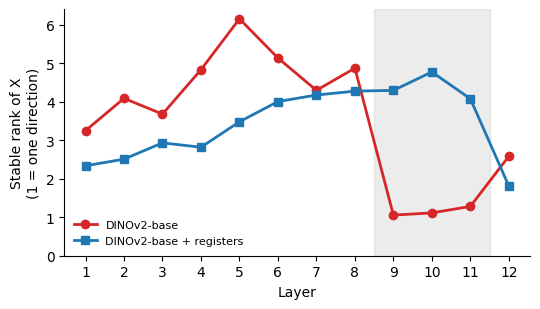

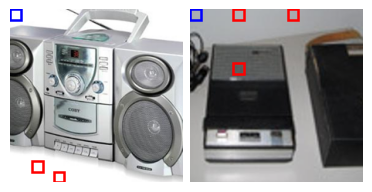

Saved fig1a_stable_rank.png/.pdf and fig1b_outliers.png/.pdf (images [3, 4] : ['cassette player', 'cassette player'] )
Blue = top-left token, red = other outlier tokens (layer 10).


In [8]:
# Cell 8 - FIGURE 1 for the proposal: (a) stable rank per layer, (b) outlier tokens on two images
# What this cell does and why: the ONE figure of the proposal. (a) shows the collapse at layers 9-11 in the standard
# model and the concentrated final layer with registers; (b) shows where the outlier tokens are.
x = A1[A1.model == "standard"].layer.values
fig, ax = plt.subplots(figsize=(5.5, 3.2))
ax.axvspan(8.5, 11.5, color="grey", alpha=0.15)
ax.plot(x, A1[A1.model == "standard"].stable_rank, "o-", color="tab:red", lw=2, label="DINOv2-base")
ax.plot(x, A1[A1.model == "registers"].stable_rank, "s-", color="tab:blue", lw=2, label="DINOv2-base + registers")
ax.set_xticks(x); ax.set_xlabel("Layer"); ax.set_ylabel("Stable rank of X\n(1 = one direction)"); ax.set_ylim(0, None)
ax.spines[["top", "right"]].set_visible(False); ax.legend(fontsize=8, frameon=False)
plt.tight_layout(); plt.savefig(f"{OUT}/fig1a_stable_rank.png", dpi=300); plt.savefig(f"{OUT}/fig1a_stable_rank.pdf"); plt.show()

m = OUTL[10]
fig, axes = plt.subplots(1, 2, figsize=(3.6, 2.0))
for ax, k in zip(axes, FIG1B_IMAGES):
    ax.imshow(imgs[k].permute(1, 2, 0).numpy()); ax.axis("off")
    for r_, c_ in zip(*np.nonzero(m[k])):
        ax.add_patch(mpatches.Rectangle((c_ * PATCH, r_ * PATCH), PATCH, PATCH, fill=False,
                                        ec="blue" if (r_, c_) == (0, 0) else "red", lw=1.8))
plt.subplots_adjust(left=0.01, right=0.99, top=0.99, bottom=0.01, wspace=0.04)
plt.savefig(f"{OUT}/fig1b_outliers.png", dpi=300); plt.savefig(f"{OUT}/fig1b_outliers.pdf"); plt.show()
print("Saved fig1a_stable_rank.png/.pdf and fig1b_outliers.png/.pdf (images", FIG1B_IMAGES, ":", [class_names[labels[k]] for k in FIG1B_IMAGES], ")")
print("Blue = top-left token, red = other outlier tokens (layer 10).")

## Part B - Is the concentration harmful or useful? (Cells 9-12)

In [9]:
# Cell 9 - B1: LINEAR PROBE on frozen features (768 -> 10 classes), one per model
# What this cell does and why: DINOv2 has no classifier, so the loss L is the cross-entropy of a small linear layer
# trained on frozen features (proposal Section 1.2). The self-test checks that damping with delta = 0 changes nothing.
for name, d in MODELS.items():
    f_tr = features(name, pixels(name, train_images))
    mu, sd = f_tr.mean(0), f_tr.std(0) + 1e-6
    lin = torch.nn.Linear(f_tr.shape[1], 10).to(device)
    opt = torch.optim.Adam(lin.parameters(), lr=1e-2, weight_decay=1e-4)
    for step in range(300):
        opt.zero_grad(); loss = F.cross_entropy(lin((f_tr - mu) / sd), y_train); loss.backward(); opt.step()
    for p in lin.parameters(): p.requires_grad_(False)
    d["probe"] = lambda f, lin=lin, mu=mu, sd=sd: lin((f - mu) / sd)
    d["base_loss"], d["base_correct"] = probe_loss(name, d["pv"])
    print(f"{name:9s}: probe accuracy on the 32 images {d['base_correct'].float().mean():.3f} | mean loss {d['base_loss'].mean():.4f}")
V0 = F.normalize(torch.randn(len(images), f_tr.shape[1]), dim=-1)
l0, _ = probe_loss("standard", MODELS["standard"]["pv"], 9, V0, 0.0)
print("self-test 2 (delta = 0 changes nothing): max difference =", f"{(l0 - MODELS['standard']['base_loss']).abs().max():.1e}")
print("Expected: accuracy about 0.95-1.00 for both models; difference about 0")

standard : probe accuracy on the 32 images 1.000 | mean loss 0.0001
registers: probe accuracy on the 32 images 0.969 | mean loss 0.1331
self-test 2 (delta = 0 changes nothing): max difference = 0.0e+00
Expected: accuracy about 0.95-1.00 for both models; difference about 0


In [10]:
# Cell 10 - B2: EXACT LOSS CHANGE when damping each top-8 direction (+ random directions = noise floor tau)
# What this cell does and why: the core test of ASRO. dL < -tau: damping helps (harmful direction); dL > tau: damping
# hurts (useful direction); otherwise neutral. tau = 95th percentile of |dL| for random unit directions.
rows = []; t0 = time.time()
for name, d in MODELS.items():
    d["svd"] = {}
    for l in PILOT_LAYERS:
        X = d["hs"][l]                                          # all tokens (the probe reads the CLS token)
        U, S, Vh = torch.linalg.svd(X, full_matrices=False)
        d["svd"][l] = dict(U=U[:, :, :K], S=S[:, :K], V=Vh[:, :K, :])
        mean_dir = F.normalize(X[:, d["n_front"]:].mean(1), dim=-1)
        R = F.normalize(torch.randn(len(images), N_RANDOM, X.shape[-1], generator=torch.Generator().manual_seed(SEED + l)), dim=-1)
        for kind, dirs in [("top", Vh[:, :K, :]), ("random", R)]:
            for k in range(dirs.shape[1]):
                for delta in DELTAS:
                    l_d, c_d = probe_loss(name, d["pv"], l, dirs[:, k, :], delta)
                    for b in range(len(images)):
                        rows.append(dict(model=name, layer=l, kind=kind, direction=k + 1, delta=delta, image=b,
                                         cos_mean=float((dirs[b, k] @ mean_dir[b]).abs()),
                                         dL_exact=float(l_d[b] - d["base_loss"][b]), correct_after=bool(c_d[b])))
        print(f"{name:9s} layer {l:2d} done ({time.time() - t0:.0f}s)")
B = pd.DataFrame(rows)
tau = (B[B.kind == "random"].groupby(["model", "layer", "delta"]).dL_exact
       .apply(lambda v: np.percentile(np.abs(v), 95)).rename("tau").reset_index())
B = B.merge(tau, on=["model", "layer", "delta"])
B["label"] = np.where(B.dL_exact < -B.tau, "harmful", np.where(B.dL_exact > B.tau, "useful", "neutral"))
B2 = (B[B.kind == "top"].groupby(["model", "layer", "delta"]).label.value_counts(normalize=True).unstack(fill_value=0).reset_index())
B2.to_csv(f"{OUT}/B2_harmful_useful_neutral.csv", index=False)
print(B2.round(3).to_string(index=False))
print("Expected (pilot v1): at delta 1 the top directions are mostly useful; harmful about 0.02-0.04 (noise level)")

standard  layer  8 done (16s)
standard  layer  9 done (32s)
standard  layer 10 done (50s)
standard  layer 12 done (67s)
registers layer  8 done (83s)
registers layer  9 done (99s)
registers layer 10 done (116s)
registers layer 12 done (133s)
    model  layer  delta  harmful  neutral  useful
registers      8    0.1    0.027    0.938   0.035
registers      8    1.0    0.039    0.703   0.258
registers      9    0.1    0.031    0.934   0.035
registers      9    1.0    0.043    0.719   0.238
registers     10    0.1    0.031    0.934   0.035
registers     10    1.0    0.043    0.762   0.195
registers     12    0.1    0.020    0.941   0.039
registers     12    1.0    0.020    0.926   0.055
 standard      8    0.1    0.023    0.930   0.047
 standard      8    1.0    0.020    0.812   0.168
 standard      9    0.1    0.035    0.941   0.023
 standard      9    1.0    0.020    0.750   0.230
 standard     10    0.1    0.031    0.934   0.035
 standard     10    1.0    0.020    0.684   0.297
 standar

In [11]:
# Cell 11 - B3: FAST TEST - first-order score s_i = -delta * sigma_i * u_i^T G v_i from ONE backward pass
# What this cell does and why: ASRO must score all directions cheaply. We compare the fast score with the exact dL of
# Cell 10: rank agreement (Spearman) and, for the cases that matter (|dL| > tau), whether the SIGN is right.
fo = []
for name, d in MODELS.items():
    for l in PILOT_LAYERS:
        G = grad_at_layer(name, d["pv"], l); s_ = d["svd"][l]
        uGv = torch.einsum("btk,btd,bkd->bk", s_["U"], G, s_["V"])
        for delta in DELTAS:
            sc = -delta * s_["S"] * uGv
            fo += [(name, l, "top", k + 1, delta, b, float(sc[b, k])) for b in range(sc.shape[0]) for k in range(K)]
B = B.drop(columns=[c for c in ["score"] if c in B]).merge(
    pd.DataFrame(fo, columns=["model", "layer", "kind", "direction", "delta", "image", "score"]),
    on=["model", "layer", "kind", "direction", "delta", "image"], how="left")
B.to_csv(f"{OUT}/B_all_damping_results.csv", index=False)
rows = []
for (name, l, delta), g in B[B.kind == "top"].groupby(["model", "layer", "delta"]):
    big = g[g.dL_exact.abs() > g.tau]
    rows.append(dict(model=name, layer=l, delta=delta, spearman=spearmanr(g.score, g.dL_exact)[0], n_large=len(big),
                     sign_agreement_large=float((np.sign(big.score) == np.sign(big.dL_exact)).mean()) if len(big) else np.nan))
B3 = pd.DataFrame(rows); B3.to_csv(f"{OUT}/B3_fast_test.csv", index=False)
print(B3.round(3).to_string(index=False))
print("Expected (pilot v1): sign agreement high at layer 12, lower at layers 8-10")

    model  layer  delta  spearman  n_large  sign_agreement_large
registers      8    0.1     0.624       16                 0.938
registers      8    1.0     0.191       76                 0.566
registers      9    0.1     0.641       17                 0.941
registers      9    1.0     0.268       72                 0.625
registers     10    0.1     0.657       17                 1.000
registers     10    1.0     0.305       61                 0.639
registers     12    0.1     0.559       15                 1.000
registers     12    1.0     0.560       19                 0.947
 standard      8    0.1     0.544       18                 1.000
 standard      8    1.0     0.149       48                 0.667
 standard      9    0.1     0.551       15                 1.000
 standard      9    1.0     0.072       64                 0.500
 standard     10    0.1     0.579       17                 1.000
 standard     10    1.0     0.082       81                 0.506
 standard     12    0.1  

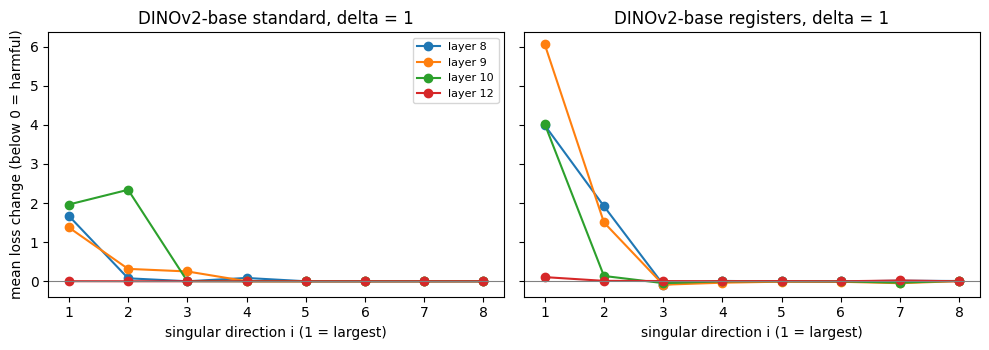

Saved B4_mean_loss_change.png and .csv


In [12]:
# Cell 12 - B4: small figure for GitHub (not for the proposal): mean loss change per direction (delta = 1)
# What this cell does and why: one picture of Part B - above 0 = removing that direction hurts (useful direction).
summ = B[B.kind == "top"].groupby(["model", "layer", "delta", "direction"]).agg(
    mean_dL=("dL_exact", "mean"), accuracy_after=("correct_after", "mean")).reset_index()
summ.to_csv(f"{OUT}/B4_mean_loss_change.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, name in zip(axes, MODELS):
    for l in PILOT_LAYERS:
        s_ = summ[(summ.model == name) & (summ.layer == l) & (summ.delta == 1.0)]
        ax.plot(s_.direction, s_.mean_dL, marker="o", label=f"layer {l}")
    ax.axhline(0, color="grey", lw=0.8); ax.set_xticks(range(1, K + 1))
    ax.set(xlabel="singular direction i (1 = largest)", title=f"DINOv2-base {name}, delta = 1")
axes[0].set_ylabel("mean loss change (below 0 = harmful)"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT}/B4_mean_loss_change.png", dpi=200); plt.show()
print("Saved B4_mean_loss_change.png and .csv")

## Part C - Does harm appear under distribution shift? (Cell 13)

In [13]:
# Cell 13 - C: THE SAME TEST ON SHIFTED IMAGES (blur, noise, higher resolution 448 px)
# What this cell does and why: ASRO expects harmful directions mainly under shift. The probe trained on CLEAN images
# is tested on shifted copies of the same 32 images; harmful / useful / neutral are counted with the same rule.
rng_s = np.random.default_rng(SEED)
def make_shift(name, shift):
    if shift == "blur": return pixels(name, [im.filter(ImageFilter.GaussianBlur(radius=3)) for im in images])
    if shift == "noise":
        noisy = [Image.fromarray(np.clip(np.asarray(im).astype(np.float32) + rng_s.normal(0, 40, np.asarray(im).shape), 0, 255).astype(np.uint8)) for im in images]
        return pixels(name, noisy)
    if shift == "high-res 448": return pixels(name, images, size=448)
rows = []; t0 = time.time()
for name, d in MODELS.items():
    rows += [dict(model=name, shift="clean", layer=l, delta=dl, accuracy=float(d["base_correct"].float().mean()),
                  harmful=float(r.get("harmful", 0)), useful=float(r.get("useful", 0)))
             for (l, dl), r in B2[B2.model == name].set_index(["layer", "delta"]).iterrows()]
    for shift in SHIFTS:
        pv = make_shift(name, shift)
        base, corr = probe_loss(name, pv)
        hs_ = hidden_states(name, pv, layers=PILOT_LAYERS)
        for l in PILOT_LAYERS:
            _, S, Vh = torch.linalg.svd(hs_[l], full_matrices=False)
            R = F.normalize(torch.randn(len(images), N_RANDOM, Vh.shape[-1], generator=torch.Generator().manual_seed(SEED + l)), dim=-1)
            for delta in DELTAS:
                top = torch.stack([probe_loss(name, pv, l, Vh[:, k, :], delta)[0] - base for k in range(K)], 1)
                rnd = torch.stack([probe_loss(name, pv, l, R[:, k, :], delta)[0] - base for k in range(N_RANDOM)], 1)
                tau_s = float(np.percentile(rnd.abs().numpy(), 95))
                rows.append(dict(model=name, shift=shift, layer=l, delta=delta, accuracy=float(corr.float().mean()),
                                 harmful=float((top < -tau_s).float().mean()), useful=float((top > tau_s).float().mean())))
        print(f"{name:9s} {shift:12s} accuracy {corr.float().mean():.2f} ({time.time() - t0:.0f}s)")
C = pd.DataFrame(rows); C.to_csv(f"{OUT}/C_shift.csv", index=False)
print(C.groupby(["model", "shift", "delta"])[["accuracy", "harmful", "useful"]].mean().round(3).to_string())
print("How to read it: if 'harmful' rises clearly above the clean level under a shift, harm appears where ASRO expects it.")

standard  blur         accuracy 1.00 (67s)
standard  noise        accuracy 1.00 (134s)
standard  high-res 448 accuracy 1.00 (486s)
registers blur         accuracy 0.97 (554s)
registers noise        accuracy 0.97 (621s)
registers high-res 448 accuracy 0.97 (969s)
                              accuracy  harmful  useful
model     shift        delta                           
registers blur         0.1       0.969    0.033   0.033
                       1.0       0.969    0.032   0.194
          clean        0.1       0.969    0.027   0.036
                       1.0       0.969    0.036   0.187
          high-res 448 0.1       0.969    0.029   0.031
                       1.0       0.969    0.037   0.169
          noise        0.1       0.969    0.032   0.039
                       1.0       0.969    0.031   0.188
standard  blur         0.1       1.000    0.052   0.045
                       1.0       1.000    0.031   0.204
          clean        0.1       1.000    0.029   0.039
         

## Summary (Cells 14-15)

In [14]:
# Cell 14 - ONE SUMMARY OF THE WHOLE PILOT STUDY: copy everything this cell prints and paste it into the Claude app
# What this cell does and why: collects the numbers that the proposal uses, in one block, and saves it as pilot_summary.md.
def rng_(s): return f"{s.min():.2f}-{s.max():.2f}"
st, rg = A1[A1.model == "standard"].set_index("layer"), A1[A1.model == "registers"].set_index("layer")
L911 = [9, 10, 11]; last = st.index.max()
lines = ["# ASRO pilot study - summary (DINOv2-base, %d Imagenette validation images, seed %d)" % (len(images), SEED), "",
 "## A. Where is the concentration?",
 f"- standard, layers 9-11: top-1 energy {rng_(st.loc[L911, 'top1_energy'])}, stable rank {rng_(st.loc[L911, 'stable_rank'])}",
 f"- outliers per image {rng_(st.loc[L911, 'outliers_per_image'])}, max/median norm {rng_(st.loc[L911, 'max_over_median_norm'])}",
 f"- stable rank without outliers {rng_(st.loc[L911, 'stable_rank_no_outliers'])}; centred {rng_(st.loc[L911, 'stable_rank_centred'])}",
 f"- standard layers 1-8: stable rank {rng_(st.loc[1:8, 'stable_rank'])}",
 f"- registers: outliers per image (all layers) max {rg['outliers_per_image'].max():.2f}; stable rank layers 9-11 {rng_(rg.loc[L911, 'stable_rank'])}",
 f"- final layer {last}: stable rank standard {st.loc[last, 'stable_rank']:.2f} -> centred {st.loc[last, 'stable_rank_centred']:.2f}; "
 f"registers {rg.loc[last, 'stable_rank']:.2f} -> centred {rg.loc[last, 'stable_rank_centred']:.2f}",
 f"- randomised SVD (2 power iterations): mean error {rng_(A2.mean_max_rel_err)}, worst {A2.worst_rel_err.max():.3f}, min cos v1 {A2.min_cos_v1.min():.4f}",
 f"- outlier location: top-left token outlier in {A3.corner_is_outlier.min():.0%}-{A3.corner_is_outlier.max():.0%} of images; "
 f"other outliers per image {rng_(A3.other_outliers_per_image)}",
 f"- plainness: median pixel std outliers {rng_(A3.median_pixel_std_outliers)} vs other {rng_(A3.median_pixel_std_other)}; "
 f"near-flat {rng_(A3.near_flat_outliers)} vs {rng_(A3.near_flat_other)}; same patches next layer {A3.same_patches_as_next_layer.dropna().round(2).tolist()}",
 "", "## B. Harmful or useful? (clean images)"]
for name, d in MODELS.items():
    lines.append(f"- {name}: probe accuracy {d['base_correct'].float().mean():.3f}")
mid = summ[(summ.delta == 1.0) & (summ.direction <= 2) & (summ.layer.isin([8, 9, 10, 11]))]
for name in MODELS:
    mm = mid[mid.model == name]
    lines.append(f"- {name}, delta 1, directions 1-2, layers 8-10: loss change {rng_(mm.mean_dL)}, accuracy after {rng_(mm.accuracy_after)}")
for dl in DELTAS:
    b2 = B2[B2.delta == dl]
    lines.append(f"- delta {dl}: harmful {rng_(b2.get('harmful', pd.Series([0.0])))}, neutral {rng_(b2.get('neutral', pd.Series([0.0])))}, useful {rng_(b2.get('useful', pd.Series([0.0])))}")
for dl in DELTAS:
    b3 = B3[B3.delta == dl]
    lines.append(f"- fast test delta {dl}: Spearman {rng_(b3.spearman)}; sign agreement (large effects) "
                 f"layer {max(PILOT_LAYERS)}: {rng_(b3[b3.layer == max(PILOT_LAYERS)].sign_agreement_large)}, "
                 f"other layers: {rng_(b3[b3.layer != max(PILOT_LAYERS)].sign_agreement_large)}")
lines += ["", "## C. Under distribution shift (mean over layers)"]
cs = C.groupby(["model", "shift", "delta"])[["accuracy", "harmful", "useful"]].mean().reset_index()
for _, r in cs.iterrows():
    lines.append(f"- {r['model']:9s} {r['shift']:12s} delta {r['delta']}: accuracy {r['accuracy']:.2f}, harmful {r['harmful']:.3f}, useful {r['useful']:.3f}")
lines += ["", f"(total run time {(time.time() - T_START) / 60:.0f} min)"]
open(f"{OUT}/pilot_summary.md", "w").write("\n".join(lines))
print("\n".join(lines))
print("\n# END - copy everything above and paste it into the Claude app")

# ASRO pilot study - summary (DINOv2-base, 32 Imagenette validation images, seed 0)

## A. Where is the concentration?
- standard, layers 9-11: top-1 energy 0.78-0.95, stable rank 1.06-1.28
- outliers per image 2.75-3.34, max/median norm 20.87-52.96
- stable rank without outliers 3.83-4.29; centred 1.05-1.24
- standard layers 1-8: stable rank 3.25-6.16
- registers: outliers per image (all layers) max 0.00; stable rank layers 9-11 4.08-4.78
- final layer 12: stable rank standard 2.59 -> centred 5.03; registers 1.81 -> centred 3.86
- randomised SVD (2 power iterations): mean error 0.01-0.01, worst 0.024, min cos v1 1.0000
- outlier location: top-left token outlier in 100%-100% of images; other outliers per image 1.75-2.34
- plainness: median pixel std outliers 0.03-0.03 vs other 0.12-0.12; near-flat 0.40-0.45 vs 0.10-0.10; same patches next layer [0.97, 0.85]

## B. Harmful or useful? (clean images)
- standard: probe accuracy 1.000
- registers: probe accuracy 0.969
- standard, delta 1, d

In [15]:
# Cell 15 - ZIP ALL RESULTS and download (run LAST)
# What this cell does and why: one zip file with every CSV, figure and the summary, ready to upload to GitHub
# (results/asro_results/; upload the files themselves, not the folder).
zip_path = shutil.make_archive(OUT, "zip", OUT)
print("Files:"); [print("   ", f) for f in sorted(os.listdir(OUT))]
print("Zip file ready:", zip_path)
try:
    from google.colab import files; files.download(zip_path)
except Exception:
    print("Not in Colab (or download blocked): folder icon on the left -> right-click the zip -> Download")

Files:
    A1_concentration_per_layer.csv
    A2_randomised_svd.csv
    A3_outlier_location.csv
    B2_harmful_useful_neutral.csv
    B3_fast_test.csv
    B4_mean_loss_change.csv
    B4_mean_loss_change.png
    B_all_damping_results.csv
    C_shift.csv
    fig1a_stable_rank.pdf
    fig1a_stable_rank.png
    fig1b_outliers.pdf
    fig1b_outliers.png
    pilot_summary.md
Zip file ready: /content/asro_pilot_study.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>